# Aprendizagem Automática (APRAU) - Trabalho de Grupo

**Mestrado em Engenharia Informática · ISEP · 2026/2027**

**Grupo 14**

|      Nome         | Nº de aluno |
|-------------------|-------------|
| Ellah Fleischmann |   1231478   |
|   Inês Martinho   |   1230806   |
#
**Docente (PL):** Elsa Ferreira Gomes · **Turma:** M1A

---

### Índice
1. Introdução
2. Preparação do ambiente e carregamento dos dados
3. Análise Exploratória de Dados (EDA)
4. Regressão
5. Classificação
6. Seleção de Variáveis (Ridge e Lasso)
7. Conclusões
8. Referências

## 1. Introdução

Este trabalho aplica diferentes métodos de aprendizagem automática a um conjunto de dados clínico multi-doença, com o objetivo de analisar o comportamento dos modelos e interpretar criticamente os resultados.

O dataset provém de um *data warehouse* (DW) médico consolidado, desenhado para estudar padrões de comorbilidade em doenças cardiometabólicas crónicas. Cada registo representa o perfil de um doente, com variáveis demográficas, antropométricas, de estilo de vida e biomarcadores laboratoriais, e tem duas variáveis alvo:

- `target_class` (categórica): categoria de diagnóstico clínico, usada na **classificação**;
- `target_regression` (contínua): medição laboratorial, usada na **regressão**.

O subconjunto atribuído ao grupo 14 tem 2000 registos e três classes de diagnóstico (DI, HT e HT_HY), com forte desbalanceamento entre elas.

**Estrutura do trabalho**

| Secção | Conteúdo |
|--------|----------|
| EDA | Estatística descritiva, análise univariada e bivariada; deteção de variáveis constantes, redundantes ou pouco informativas |
| Regressão | Regressão linear simples e múltipla, comparadas com R², MAE e RMSE |
| Classificação | Regressão logística e LDA, com holdout, CV (k=5 e k=10), LOOCV e bootstrap |
| Seleção de variáveis | Ridge e Lasso: todas as variáveis vs. conjunto reduzido |

## 2. Preparação do ambiente e carregamento dos dados

Nesta secção importamos as bibliotecas, fixamos a semente aleatória (para os resultados serem reprodutíveis) e carregamos o dataset. Fazemos ainda uma verificação inicial da dimensão, dos tipos de dados e da distribuição da variável alvo de classificação.

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

SEED = 42 # semente usada em todo o trabalho

In [4]:
df = pd.read_csv("../data/dataset_grupo_14.csv")

print(df.shape)
df.head()

(2000, 35)


,age_level,gender,bmi_level,smoking,age,age_normalized,bmi,HbA1c_level,cholesterol,sleep_hours,...,hdl,ldl,education_level,employment_status,systolic_index,calcium_baseline,plasma_value,ldl_alternative,target_regression,target_class
0,Senior,Male,Overweight,Never,82,0.919540,29.20,7.003349,207.00000,8.000000,...,79.000000,160.000000,Primary,Retired,137.000000,9.42,1.094354,128.408780,194.0,DI
1,Senior,Female,Overweight,Never,80,0.896552,27.32,6.500000,224.41791,7.179453,...,64.012168,129.853982,Primary,Retired,136.462389,9.42,1.339049,97.000000,160.0,DI
2,Senior,Male,Normal,Never,73,0.816091,21.10,7.010714,175.00000,5.900000,...,45.000000,106.000000,Secondary,Employed,133.000000,9.42,1.415402,112.000000,104.0,DI
3,Senior,Female,Obese,Former,85,0.954022,34.80,6.865766,163.00000,5.500000,...,98.000000,116.000000,Tertiary,Employed,95.000000,9.42,1.173173,128.585774,195.0,DI
4,Senior,Male,Overweight,Former,69,0.770114,28.90,6.993220,172.00000,6.900000,...,31.000000,97.000000,Tertiary,Retired,128.000000,9.42,1.210187,152.000000,171.0,DI


### 2.1 Estrutura e tipos de dados

Verificamos os tipos de cada coluna e a existência de valores em falta.

In [5]:
df.info()
print("\nValores em falta por coluna:")
print(df.isnull().sum()[df.isnull().sum() > 0])

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 35 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   age_level             2000 non-null   object 
 1   gender                2000 non-null   object 
 2   bmi_level             2000 non-null   object 
 3   smoking               2000 non-null   object 
 4   age                   2000 non-null   int64  
 5   age_normalized        2000 non-null   float64
 6   bmi                   2000 non-null   float64
 7   HbA1c_level           2000 non-null   float64
 8   cholesterol           2000 non-null   float64
 9   sleep_hours           2000 non-null   float64
 10  triglycerides         2000 non-null   float64
 11  physical_activity     2000 non-null   object 
 12  family_history        2000 non-null   object 
 13  stress_level          2000 non-null   object 
 14  low_hdl_cholesterol   2000 non-null   object 
 15  high_ldl_cholesterol 

### 2.2 Distribuição da variável alvo de classificação

Como o enunciado indica que a maioria dos grupos trabalha com um dataset desbalanceado, é importante perceber desde já a proporção de cada classe, pois isso condiciona a escolha das métricas de avaliação.

In [6]:
print(df['target_class'].value_counts())
print()
print(df['target_class'].value_counts(normalize=True).round(3))

target_class
DI       1714
HT        183
HT_HY     103
Name: count, dtype: int64

target_class
DI       0.857
HT       0.092
HT_HY    0.052
Name: proportion, dtype: float64


### 2.3 Separação dos tipos de variáveis

Separamos as variáveis categóricas das numéricas, excluindo os dois alvos, para as reutilizarmos ao longo da análise.

In [7]:
cat_cols = df.select_dtypes(include=['object', 'string']).columns.drop('target_class').tolist()
num_cols = df.select_dtypes(include=['number']).columns.drop('target_regression').tolist()

print(f"Categóricas: ({len(cat_cols)}) {cat_cols}")
print(f"Numéricas: ({len(num_cols)}) {num_cols}")

Categóricas: (12) ['age_level', 'gender', 'bmi_level', 'smoking', 'physical_activity', 'family_history', 'stress_level', 'low_hdl_cholesterol', 'high_ldl_cholesterol', 'sugar_consumption', 'education_level', 'employment_status']
Numéricas: (21) ['age', 'age_normalized', 'bmi', 'HbA1c_level', 'cholesterol', 'sleep_hours', 'triglycerides', 'blood_pressure', 'crp_level', 'homocysteine_level', 'systolic_bp', 'diastolic_bp', 'alcohol_intake', 'salt_intake', 'heart_rate', 'hdl', 'ldl', 'systolic_index', 'calcium_baseline', 'plasma_value', 'ldl_alternative']


## 3. Análise Exploratória de Dados (EDA)

### 3.1 Estatística descritiva

Começamos por resumir numericamente as variáveis. Para as numéricas, analisamos medidas de tendência central (média, mediana), dispersão (desvio-padrão, quartis, amplitude) e assimetria. Para as categóricas, analisamos a frequência de cada categoria. Esta análise permite detetar à partida variáveis constantes, valores fora do intervalo esperado e possíveis outliers.

In [8]:
desc = df[num_cols].describe().T
desc['skew'] = df[num_cols].skew()
desc['nunique'] = df[num_cols].nunique()
desc.round(3)

,count,mean,std,min,25%,50%,75%,max,skew,nunique
age,2000.0,55.404,20.119,7.000,39.000,58.000,73.000,89.000,-0.200,78
age_normalized,2000.0,0.614,0.231,0.057,0.425,0.644,0.816,1.000,-0.200,141
bmi,2000.0,28.086,7.078,15.000,22.600,27.320,33.590,59.270,0.269,744
HbA1c_level,2000.0,6.710,0.776,3.500,6.592,6.890,7.003,9.000,-0.882,131
cholesterol,2000.0,223.302,36.367,150.000,198.000,224.527,247.000,300.000,0.003,245
sleep_hours,2000.0,6.925,1.514,4.000,5.800,6.985,7.998,10.000,0.033,339
triglycerides,2000.0,172.755,69.580,50.000,120.750,163.000,232.418,400.000,0.341,371
blood_pressure,2000.0,150.213,5.811,120.000,149.008,149.968,151.152,180.000,0.451,159
crp_level,2000.0,7.381,1.420,0.024,7.295,7.458,7.706,14.945,-0.526,289
homocysteine_level,2000.0,12.357,1.449,5.046,12.259,12.417,12.638,19.992,-0.446,289


In [9]:
for col in cat_cols:
    print(f"--- {col} ---")
    print(df[col].value_counts())
    print()

--- age_level ---
age_level
Senior    667
Mature    646
Middle    547
Young     140
Name: count, dtype: int64

--- gender ---
gender
Male      1026
Female     974
Name: count, dtype: int64

--- bmi_level ---
bmi_level
Obese          783
Overweight     517
Normal         514
Underweight    186
Name: count, dtype: int64

--- smoking ---
smoking
Never      744
Former     654
Current    602
Name: count, dtype: int64

--- physical_activity ---
physical_activity
High        810
Moderate    600
Low         590
Name: count, dtype: int64

--- family_history ---
family_history
No     1086
Yes     914
Name: count, dtype: int64

--- stress_level ---
stress_level
Low       709
High      662
Medium    629
Name: count, dtype: int64

--- low_hdl_cholesterol ---
low_hdl_cholesterol
No     1598
Yes     402
Name: count, dtype: int64

--- high_ldl_cholesterol ---
high_ldl_cholesterol
Yes    1023
No      977
Name: count, dtype: int64

--- sugar_consumption ---
sugar_consumption
Low       743
Medium    646


In [10]:
print("Linhas duplicadas:", df.duplicated().sum())
print("\nEstatísticas do alvo de regressão:")
print(df['target_regression'].describe().round(3))

Linhas duplicadas: 0

Estatísticas do alvo de regressão:
count    2000.000
mean      141.429
std        45.440
min        70.000
25%       107.000
50%       140.000
75%       163.000
max       300.000
Name: target_regression, dtype: float64


In [11]:
# Redundância: cópias exatas e correlação
print("ldl == ldl_alternative:", df['ldl'].equals(df['ldl_alternative']))
print("systolic_bp == systolic_index:", df['systolic_bp'].equals(df['systolic_index']))
print("corr(age, age_normalized):", df['age'].corr(df['age_normalized']).round(4))

ldl == ldl_alternative: False
systolic_bp == systolic_index: True
corr(age, age_normalized): 1.0


In [12]:
# Outliers pela regra do IQR (1.5 x IQR)
Q1 = df[num_cols].quantile(0.25)
Q3 = df[num_cols].quantile(0.75)
IQR = Q3 - Q1
fora = (df[num_cols] < Q1 - 1.5 * IQR) | (df[num_cols] > Q3 + 1.5 * IQR)

n_out = fora.sum()
n_out[n_out > 0].sort_values(ascending=False)

HbA1c_level           330
crp_level             294
blood_pressure        262
homocysteine_level    246
systolic_bp           131
systolic_index        131
diastolic_bp           65
salt_intake            48
hdl                    34
plasma_value           19
bmi                     9
triglycerides           1
alcohol_intake          1
dtype: int64

**Outliers**

As variáveis com mais outliers (`HbA1c_level`, `crp_level`, `blood_pressure`, `homocysteine_level`) têm um IQR muito estreito: metade dos valores está concentrada perto da média (ex.: `blood_pressure` entre 149 e 151). Isto indica que muitos valores foram provavelmente imputados com a média, pelo que os "outliers" detetados são, em grande parte, os valores reais medidos. Por esta razão **não removemos outliers**.

In [13]:
diff = (df['ldl'] - df['ldl_alternative']).abs()
print("Linhas diferentes:", (diff > 0).sum())
print("Mesmos valores, ordem diferente:", np.allclose(np.sort(df['ldl']), np.sort(df['ldl_alternative'])))
print("Correlação:", df['ldl'].corr(df['ldl_alternative']).round(4))

Linhas diferentes: 1985
Mesmos valores, ordem diferente: True
Correlação: -0.0154


**Conclusões da estatística descritiva**

- Não existem valores em falta nem linhas duplicadas.
- `calcium_baseline` é **constante** (desvio-padrão 0; valor único 9,42), logo não tem informação → removida.
- `systolic_index` é uma **cópia exata** de `systolic_bp` → removida.
- `age_normalized` é uma transformação linear de `age` (correlação = 1) → redundante, removida.
- `ldl_alternative` contém os mesmos valores de `ldl` mas por outra ordem (correlação ≈ −0,015): é uma permutação aleatória, sem relação com o doente → ruído, removida.
- `age_level` e `bmi_level` são derivadas de `age` e `bmi`; avaliamos na análise bivariada se acrescentam informação.
- A classe alvo está muito desbalanceada (DI 85,7%, HT 9,2%, HT_HY 5,2%), o que obriga a usar métricas como F1-macro e recall por classe, e não apenas accuracy.

### 3.2 Análise univariada

Analisamos a distribuição de cada variável individualmente: histogramas para as numéricas e gráficos de barras para as categóricas. O objetivo é perceber a forma das distribuições (simétricas, assimétricas, multimodais), identificar valores atípicos e categorias muito raras, e confirmar visualmente os problemas detetados na estatística descritiva.

c:\Users\inesm\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
c:\Users\inesm\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
c:\Users\inesm\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
c:\Users\inesm\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating

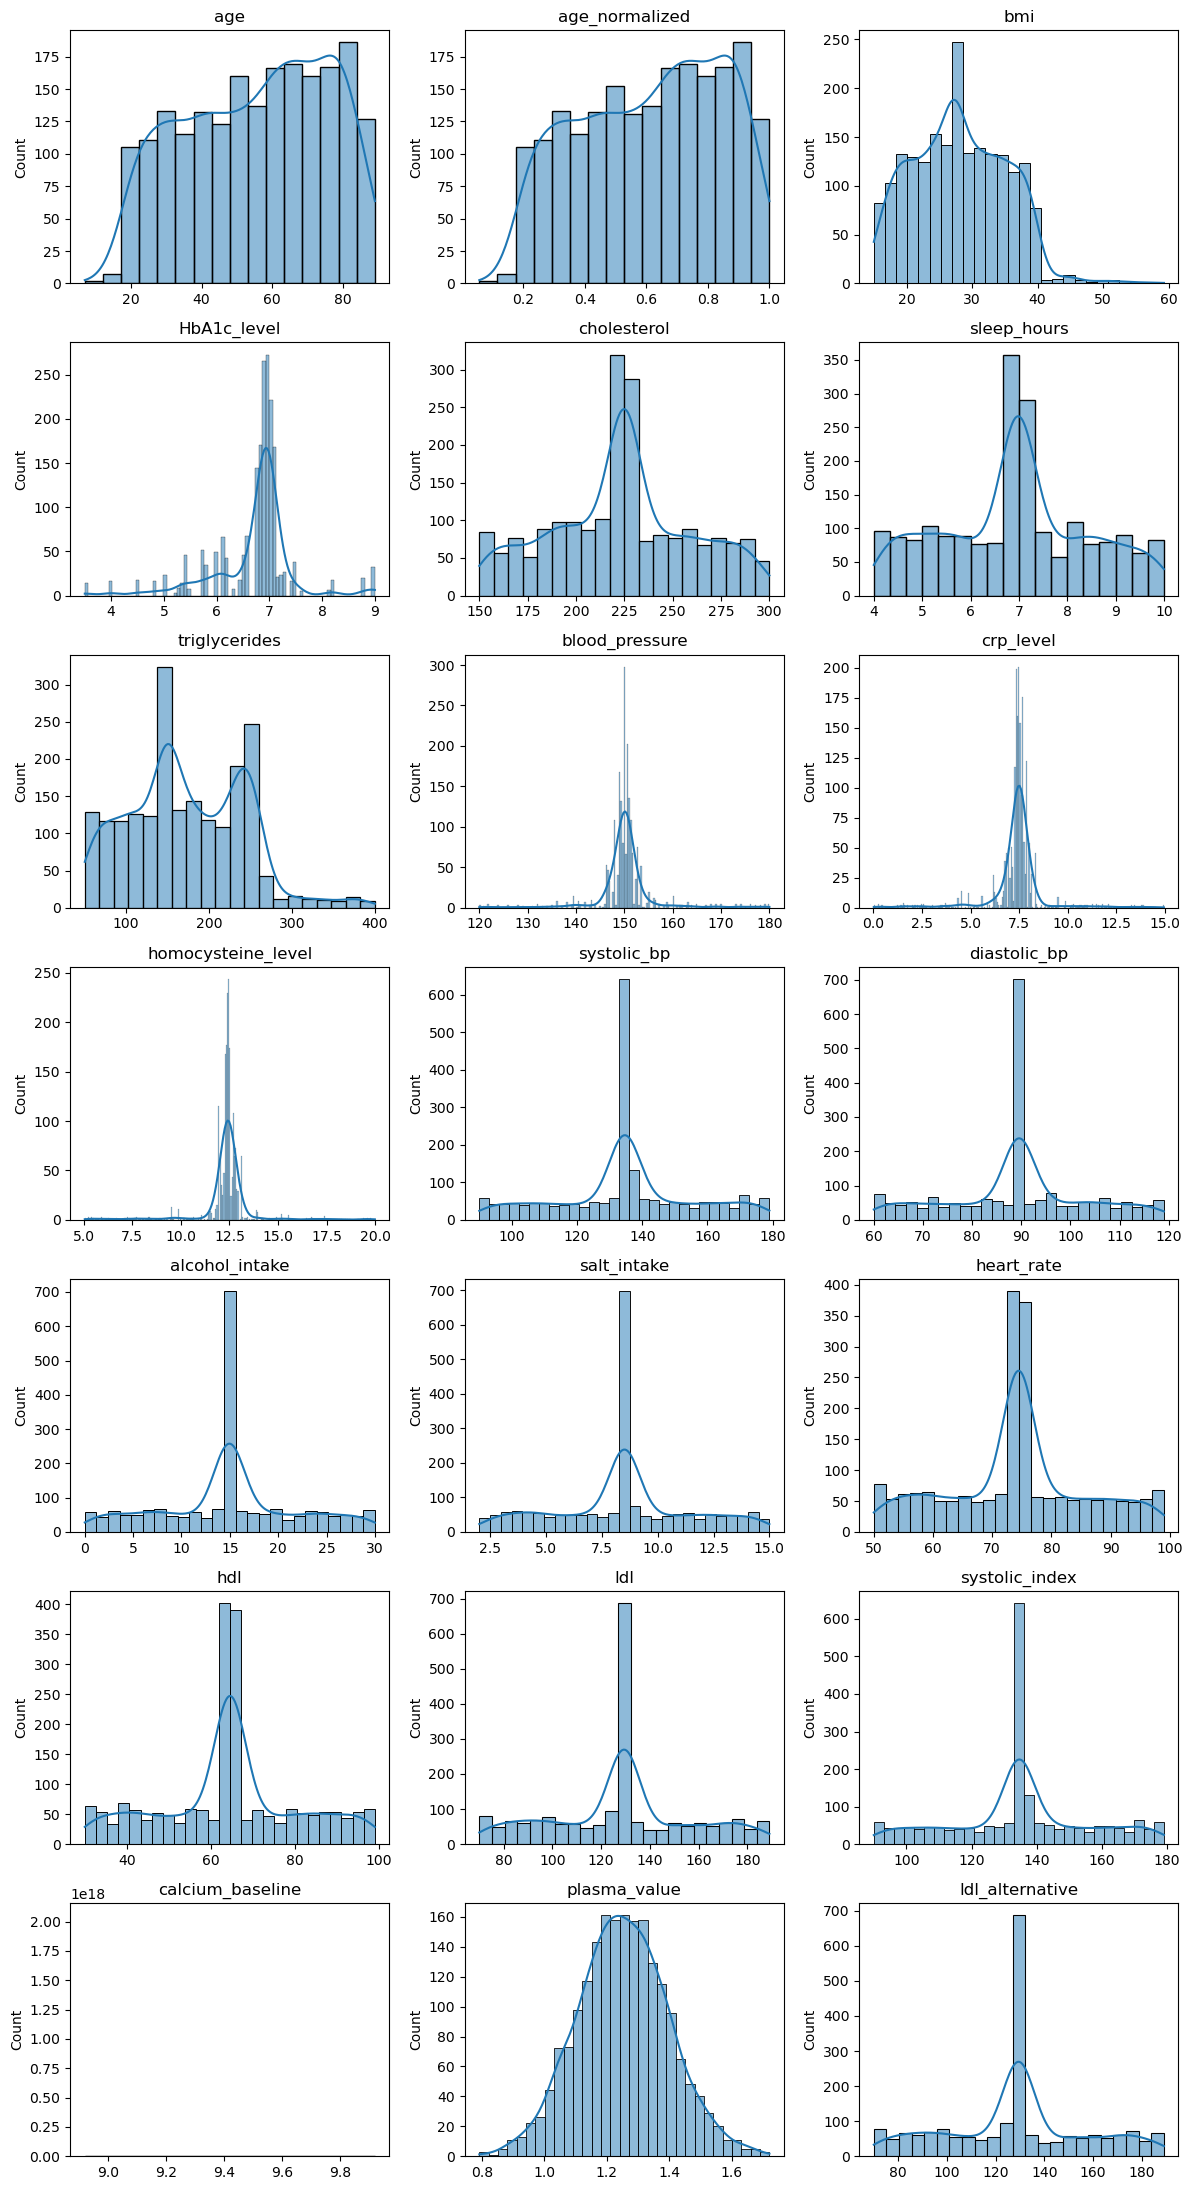

In [14]:
fig, axes = plt.subplots(7, 3, figsize=(12, 22))
for ax, col in zip(axes.ravel(), num_cols):
    sns.histplot(df[col], kde=True, ax=ax)
    ax.set_title(col)
    ax.set_xlabel('')
plt.tight_layout()
plt.show()

**Interpretação: variáveis numéricas**

- **Valores imputados:** a maioria das variáveis numéricas (`bmi`, `cholesterol`, `sleep_hours`, `systolic_bp`, `diastolic_bp`, `alcohol_intake`, `salt_intake`, `heart_rate`, `hdl`, `ldl`) apresenta um pico muito acentuado num único valor central, que chega a concentrar cerca de 700 doentes (≈35% dos dados). Fora desse pico, a distribuição é aproximadamente **uniforme**. Este padrão indica que os valores em falta foram preenchidos com a média. A assimetria próxima de 0 destas variáveis resulta de o pico estar no centro, e não de terem uma distribuição normal.
- `blood_pressure`, `crp_level`, `homocysteine_level` e `HbA1c_level` estão muito concentradas num intervalo estreito, com caudas longas e pouco povoadas. É por isso que a regra do IQR deteta tantos outliers nestas variáveis.
- `HbA1c_level` tem assimetria negativa (−0,88): a maioria dos valores está perto de 7 e a cauda estende-se para valores mais baixos (até 3,5).
- `triglycerides` é **bimodal**, com picos perto de 150 e de 240, e uma cauda até 400.
- `age` está concentrada em idades mais elevadas, com muito poucos doentes abaixo dos 20 anos.
- `plasma_value` é a única variável com distribuição aproximadamente **normal** e tem um valor diferente para cada doente. Pode tratar-se de ruído, o que será verificado na análise bivariada.
- `calcium_baseline` não é representada no histograma por ser **constante** (valor único 9,42).
- `age` e `age_normalized` têm a mesma forma, tal como `systolic_bp` e `systolic_index`, e `ldl` e `ldl_alternative`, o que confirma a redundância já identificada.

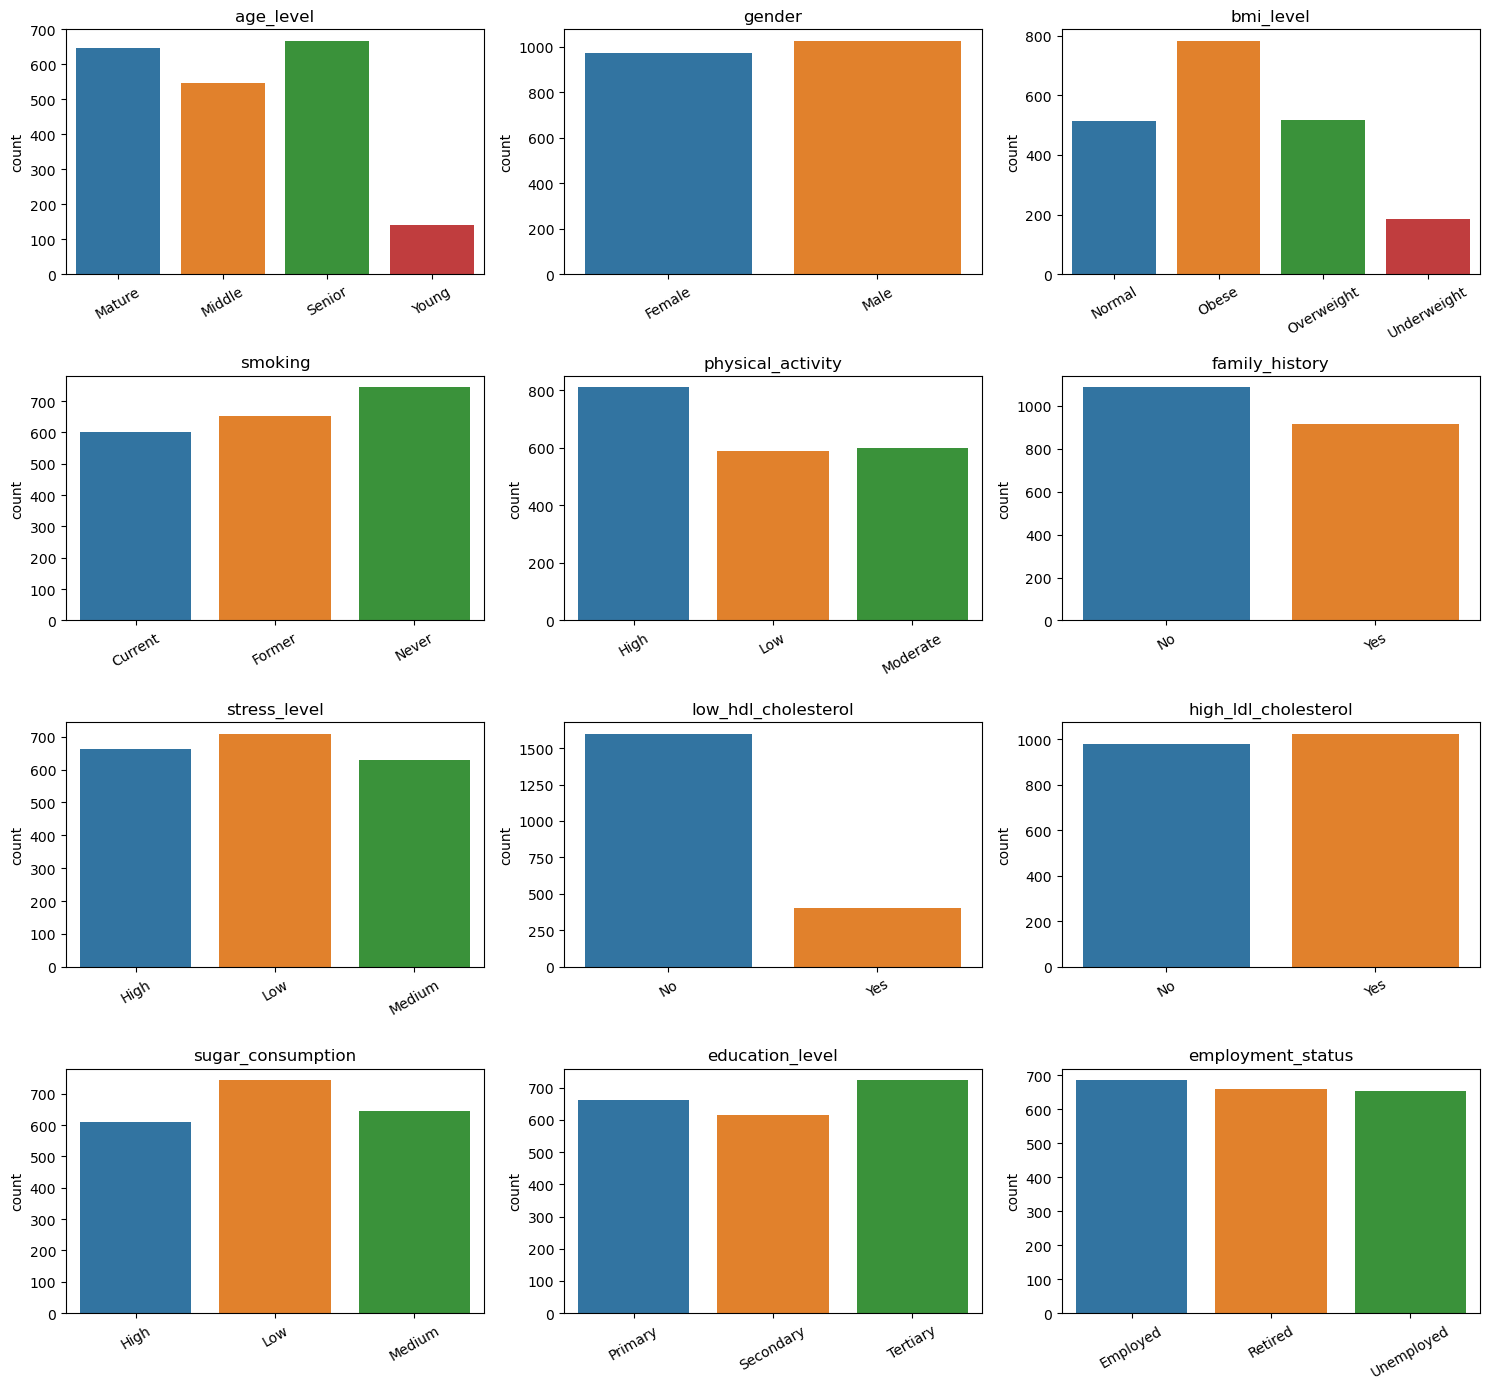

In [15]:
fig, axes = plt.subplots(4, 3, figsize=(15, 14))
for ax, col in zip(axes.ravel(), cat_cols):
    sns.countplot(x=df[col], ax=ax, order=sorted(df[col].unique()))
    ax.set_title(col)
    ax.set_xlabel('')
    ax.tick_params(axis='x', rotation=30)
plt.tight_layout()
plt.show()

**Interpretação: variáveis categóricas**

- A maioria das variáveis categóricas está bem equilibrada entre categorias (ex.: `gender`, `smoking`, `stress_level`, `education_level`, `employment_status`).
- `age_level` tem poucos doentes na categoria "Young" (140, cerca de 7%).
- `bmi_level` tem poucos doentes "Underweight" (186) e uma maioria "Obese" (783), o que é coerente com um estudo sobre doenças cardiometabólicas.
- `low_hdl_cholesterol` está desequilibrada: só 402 doentes (20%) têm "Yes".
- Nenhuma variável categórica é constante, e não há categorias com tão poucos casos que justifiquem ser agrupadas.

In [16]:
cols = ['systolic_bp', 'ldl', 'alcohol_intake', 'hdl', 'HbA1c_level']
df.groupby('target_class')[cols].agg(['mean', 'std']).round(2)

systolic_bp            ldl        alcohol_intake          hdl  \
                    mean    std    mean    std           mean   std   mean   
target_class                                                                 
DI                134.94  22.72  128.12  31.18          14.86  7.67  64.45   
HT                134.51   0.91  129.33   1.48          15.00  0.28  64.56   
HT_HY             134.50   0.87  129.44   1.38          14.95  0.28  64.61   

                    HbA1c_level        
                std        mean   std  
target_class                           
DI            17.89        6.93  0.51  
HT             0.52        5.41  0.84  
HT_HY          0.47        5.40  0.77